# Projekt: Wstępne przetwarzanie danych - zbiór Titanic
**Cel:** Przygotowanie danych do modelowania z wykorzystaniem dobrych praktyk inżynierii cech oraz zapobieganiem wyciekowi danych (Data Leakage).

In [148]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
df = pd.read_csv("titanic.csv")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


## 1. Analiza Jakości Danych
metryki jakości danych, z zwróceniem uwagi na ich **kompletność**

In [149]:
df.info()

print("\n\nKompletność procent braków:")
missing_data = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({'Braki': missing_data, 'Procent (%)': missing_percent})
display(missing_df[missing_df['Braki'] > 0].sort_values(by='Procent (%)', ascending=False))

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


Kompletność procent braków:


,Braki,Procent (%)
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467


# Cabin (>77% braków) - kwalifikuje się do usunięcia lub zmiany na flagę
# Age (~20% braków) - zastosujemy imputację grupową
# Embarked (<1% braków) - prosta imputacja modą

## 2. Statystyki opisowe i rozkłady
W celu analizy wartości odstających (kwartyle, średnia, min, max).

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


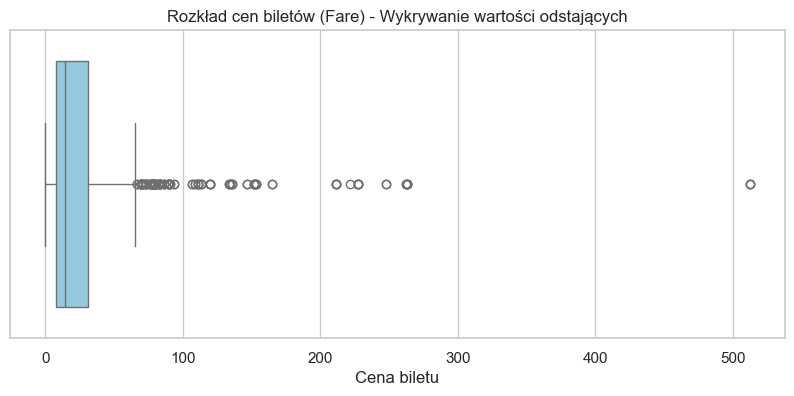

In [150]:
display(df.describe())

# Wizualizacja ceny
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['Fare'], color='skyblue')
plt.title('Rozkład cen biletów (Fare) - Wykrywanie wartości odstających')
plt.xlabel('Cena biletu')
plt.show()



# Widzimy silne skrzywienie i wartości odstające (np. bilet za >500) oznaczająca konieczność użycia skalera.

## 3. Inżynieria Cech (Feature Engineering)
Tworzymy nowe zmienne na podstawie istniejących, co ułatwi modelowi pracę.

In [151]:
data = df.copy()
data['Title'] = data['Name'].str.extract(' ([A-Za-z]+)\\.', expand=False)

# Zamiana mało popularnych tytułów na wspólną kategorię
otherTitles = ['Lady', 'Countess','Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona']
data['Title'] = data['Title'].replace(otherTitles, 'Other')
data['Title'] = data['Title'].replace('Mlle', 'Miss')
data['Title'] = data['Title'].replace('Ms', 'Miss')
data['Title'] = data['Title'].replace('Mme', 'Mrs')

print("Rozkład nowych tytułów pasażerów:")
print(data['Title'].value_counts())

# B) Rozmiar rodziny
# SibSp (rodzeństwo/małżonek) + Parch (rodzice/dzieci) + 1 (sam pasażer)
data['FamilySize'] = data['SibSp'] + data['Parch'] + 1

data['IsAlone'] = 0
data.loc[data['FamilySize'] == 1, 'IsAlone'] = 1 # 1 oznacza, że pasażer podróżuje sam

# C) Czy miał przypisaną kabinę
data['Has_Cabin'] = data['Cabin'].apply(lambda x: 0 if type(x) == float else 1)

data[['Name', 'Title', 'FamilySize', 'IsAlone', 'Has_Cabin']]

Rozkład nowych tytułów pasażerów:
Title
Mr        517
Miss      185
Mrs       126
Master     40
Other      23
Name: count, dtype: int64


,Name,Title,FamilySize,IsAlone,Has_Cabin
0,"Braund, Mr. Owen Harris",Mr,2,0,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,2,0,1
2,"Heikkinen, Miss. Laina",Miss,1,1,0
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,2,0,1
4,"Allen, Mr. William Henry",Mr,1,1,0
...,...,...,...,...,...
886,"Montvila, Rev. Juozas",Other,1,1,0
887,"Graham, Miss. Margaret Edith",Miss,1,1,1
888,"Johnston, Miss. Catherine Helen ""Carrie""",Miss,4,0,0
889,"Behr, Mr. Karl Howell",Mr,1,1,1


## 4. Strategia walidacji i imputacja grupowa
Dla kolumny `Age` (ok. 20% braków) zastosujemy **imputację zależną od grup**.

Definiujemy zmienne objaśniające (X) oraz zmienną celu (y) i dokonamy podziału danych, pamiętając o unikaniu zjawiska **Data Leakage**.

In [152]:
age_medians = data.groupby('Title')['Age'].transform('median')
data['Age'] = data['Age'].fillna(age_medians)

# B) Definiujemy cechy (X) oraz cel (y)
X = data.drop(columns=['PassengerId', 'Survived', 'Name', 'Ticket', 'Cabin'])
y = data['Survived']

# C) Podział na zbiór treningowy i walidacyjny (80% / 20%)
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Rozmiar zbioru treningowego: {X_train.shape}")
print(f"Rozmiar zbioru walidacyjnego: {X_val.shape}")

Rozmiar zbioru treningowego: (712, 11)
Rozmiar zbioru walidacyjnego: (179, 11)


## 5. Budowa potoku przetwarzania — Pipeline & ColumnTransformer (Wykład 5 i 6)
1. Braki w danych uzupełnione przed enkodowaniem.
2. Zastosowanie `OneHotEncoder` dla zmiennych kategorycznych nominalnych.
3. Dla numerycznych `StandardScaler`.
4. Wywołanie `.fit_transform()` **WYŁĄCZNIE na zbiorze treningowym**, a na walidacyjnym `.transform()`, co zabezpiecza nas przed **Data Leakage**.

In [153]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer


num_features = ['Age', 'Fare', 'FamilySize']
cat_features = ['Sex', 'Embarked', 'Title']
passthrough_features = ['Pclass', 'IsAlone', 'Has_Cabin']

# 1. cechy numeryczne
num_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])

# 2. cechy kategoryczne
cat_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])

# 3. Łączenie transformatorów
preprocessor = ColumnTransformer(transformers=[('num', num_transformer, num_features), ('cat', cat_transformer, cat_features), ('pass', 'passthrough', passthrough_features)])

# 4. Dopasowanie preprocessora do danych treningowych i transformacja
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

encoded_cat_names = preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_features)
all_feature_names = num_features + list(encoded_cat_names) + passthrough_features

X_train_ready = pd.DataFrame(X_train_processed, columns=all_feature_names)
display(X_train_ready.head())

,Age,Fare,FamilySize,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Other,Pclass,IsAlone,Has_Cabin
0,0.036076,0.513812,-0.556339,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,3.0,1.0,0.0
1,0.036076,-0.662563,-0.556339,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,2.0,1.0,0.0
2,0.036076,3.955399,-0.556339,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,1.0
3,-0.868950,-0.467874,0.073412,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,3.0,0.0,0.0
4,0.111495,-0.115977,0.703162,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,2.0,0.0,0.0


## 6. Korelacja i współliniowość
Szukamy cech, które są silnie skorelowane ze zmienną celu oraz tych zbyt skorelowanych między sobą (tzw. współliniowość). 

Dokonanie *selekcji cech* jako alternatywy dla PCA. Analizę przeprowadzamy na danych już przetworzonych (`X_train_ready`).

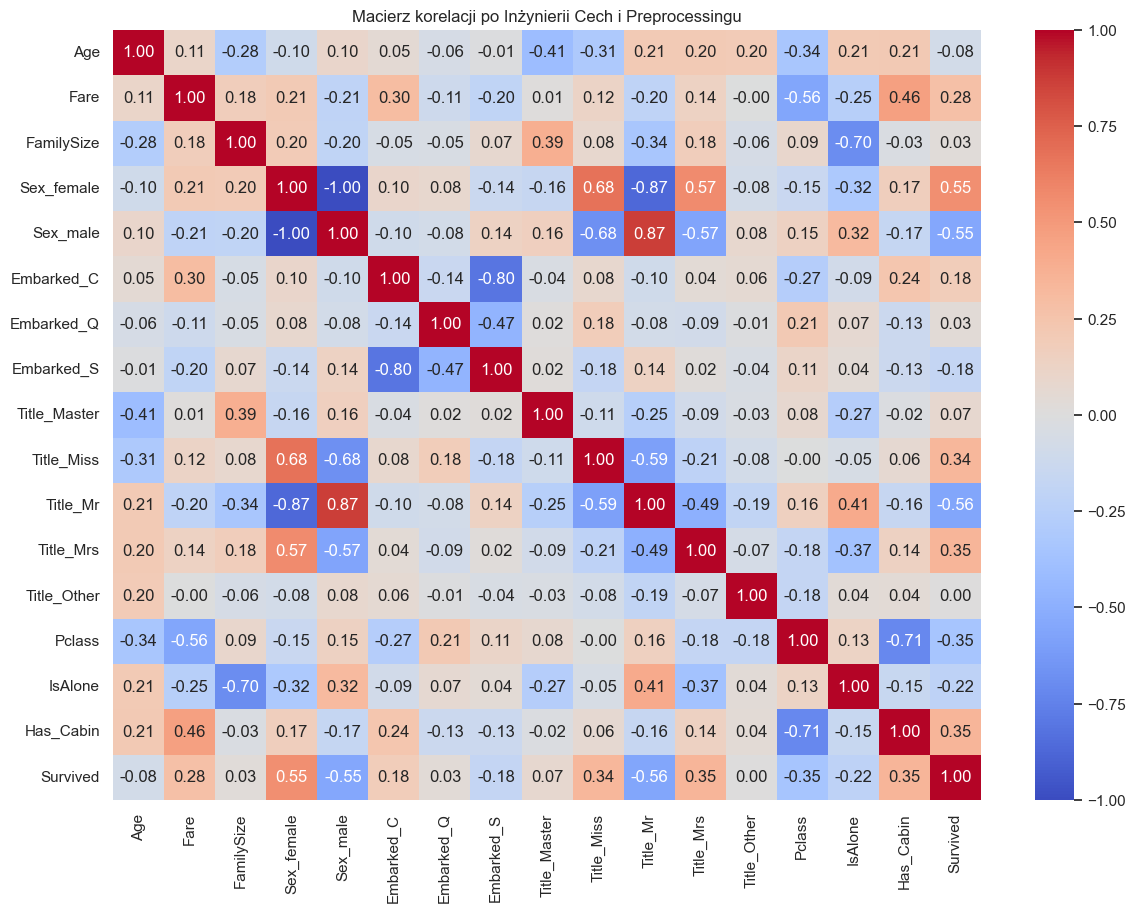

In [154]:
import matplotlib.pyplot as plt
import seaborn as sns

# tymczasowo zmienna celu
X_train_corr = X_train_ready.copy()
X_train_corr['Survived'] = y_train.reset_index(drop=True)

# Obliczanie macierzy korelacji
corr_matrix = X_train_corr.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Macierz korelacji po Inżynierii Cech i Preprocessingu')
plt.show()

# WNIOSKI (Storytelling dla prowadzącego):
# 1. Silna korelacja z 'Survived': Tytuł_Mr (ujemna, dorośli mężczyźni rzadko przeżywali), Sex_female (dodatnia).
# 2. Współliniowość: Widzimy silną korelację między 'FamilySize' a 'IsAlone' (co jest logiczne). 
#    Model drzewiasty poradzi sobie z tym dobrze, ale dla modeli liniowych moglibyśmy jedną z tych cech odrzucić.
# 3. Pclass (klasa) jest silnie ujemnie skorelowana z Fare (ceną) - bilet 1 klasy był drogi.

## 7. Budowa ostatecznego potoku z modelem (End-to-End Pipeline)
Zgodnie z dobrymi praktykami w inżynierii danych, łączymy nasz wcześniejszy `ColumnTransformer` (przygotowujący dane) z właściwym estymatorem (algorytmem uczenia maszynowego). 
Użyjemy klasyfikatora Random Forest (Las Losowy). Dzięki takiemu potokowi nowe, surowe dane z Kaggle (`test.csv`) mogą być natychmiast wrzucone do modelu bez ręcznego przekształcania!

--- Wyniki Modelu (Random Forest) ---
Dokładność (Accuracy): 0.8101

Raport Klasyfikacji:
              precision    recall  f1-score   support

           0       0.82      0.88      0.85       110
           1       0.79      0.70      0.74        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.81      0.81      0.81       179



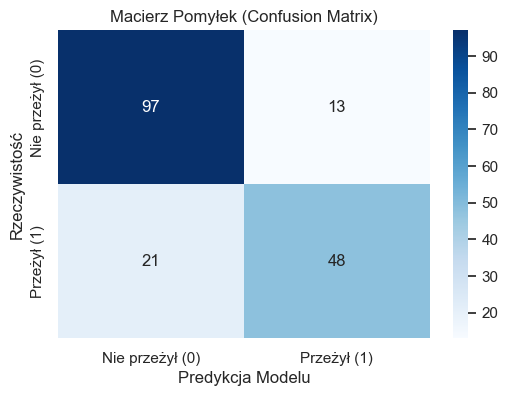

In [155]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


full_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42))])

full_pipeline.fit(X_train, y_train)

y_pred = full_pipeline.predict(X_val)

print("--- Wyniki Modelu (Random Forest) ---")
print(f"Dokładność (Accuracy): {accuracy_score(y_val, y_pred):.4f}\n")
print("Raport Klasyfikacji:")
print(classification_report(y_val, y_pred))

conf_mat = confusion_matrix(y_val, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues', xticklabels=['Nie przeżył (0)', 'Przeżył (1)'], yticklabels=['Nie przeżył (0)', 'Przeżył (1)'])
plt.ylabel('Rzeczywistość')
plt.xlabel('Predykcja Modelu')
plt.title('Macierz Pomyłek (Confusion Matrix)')
plt.show()

## 8. Interpretowalność modelu (Feature Importance)


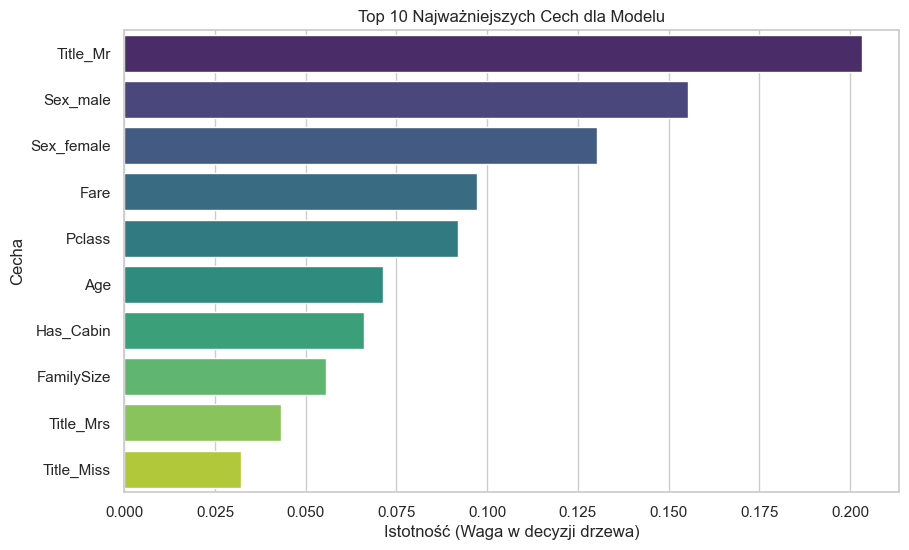

In [156]:
trained_model = full_pipeline.named_steps['classifier']

importances = trained_model.feature_importances_

feature_importance_df = pd.DataFrame({'Cecha': all_feature_names,'Istotność': importances}).sort_values(by='Istotność', ascending=False)

# Rysowanie wykresu
plt.figure(figsize=(10, 6))
sns.barplot(x='Istotność', y='Cecha', hue='Cecha', data=feature_importance_df.head(10), palette='viridis', legend=False)
plt.title('Top 10 Najważniejszych Cech dla Modelu')
plt.xlabel('Istotność (Waga w decyzji drzewa)')
plt.ylabel('Cecha')
plt.show()

## 9. Analiza Błędów Modelu (Error Analysis)

In [157]:

error_analysis_df = X_val.copy()

# Dodajemy kolumny z rzeczywistym wynikiem i naszą predykcją
error_analysis_df['Rzeczywistosc'] = y_val
error_analysis_df['Predykcja'] = y_pred

# Filtrujemy tylko te wiersze, gdzie model się pomylił
bledy = error_analysis_df[error_analysis_df['Rzeczywistosc'] != error_analysis_df['Predykcja']]

print(f"Model popełnił łącznie {len(bledy)} błędów na {len(X_val)} pasażerów w zbiorze walidacyjnym.\n")

# Typ 1: Model myślał, że pasażer przeżył (Predykcja=1), ale pasażer zginął (Rzeczywistosc=0) - tzw. False Positives
false_positives = bledy[(bledy['Predykcja'] == 1) & (bledy['Rzeczywistosc'] == 0)]
print("--- Przykład: Pasażerowie, którzy mieli przeżyć, ale zginęli (False Positives) ---")
display(false_positives[['Pclass', 'Sex', 'Age', 'Fare', 'Title', 'FamilySize']])

# Typ 2: Model myślał, że pasażer zginął (Predykcja=0), ale pasażer przeżył (Rzeczywistosc=1) - tzw. False Negatives
false_negatives = bledy[(bledy['Predykcja'] == 0) & (bledy['Rzeczywistosc'] == 1)]
print("\n--- Przykład: Pasażerowie, którzy mieli zginąć, ale przeżyli (False Negatives) ---")
display(false_negatives[['Pclass', 'Sex', 'Age', 'Fare', 'Title', 'FamilySize']])

Model popełnił łącznie 34 błędów na 179 pasażerów w zbiorze walidacyjnym.

--- Przykład: Pasażerowie, którzy mieli przeżyć, ale zginęli (False Positives) ---


,Pclass,Sex,Age,Fare,Title,FamilySize
536,1,male,45.0,26.5500,Other,1
745,1,male,70.0,71.0000,Other,3
297,1,female,2.0,151.5500,Miss,4
564,3,female,21.0,8.0500,Miss,1
502,3,female,21.0,7.6292,Miss,1
578,3,female,35.0,14.4583,Mrs,2
38,3,female,18.0,18.0000,Miss,3
593,3,female,21.0,7.7500,Miss,3
501,3,female,21.0,7.7500,Miss,1
245,1,male,44.0,90.0000,Other,3



--- Przykład: Pasażerowie, którzy mieli zginąć, ale przeżyli (False Negatives) ---


,Pclass,Sex,Age,Fare,Title,FamilySize
553,3,male,22.0,7.2250,Mr,1
712,1,male,48.0,52.0000,Mr,2
455,3,male,29.0,7.8958,Mr,1
489,3,male,9.0,15.9000,Master,3
165,3,male,9.0,20.5250,Master,3
17,2,male,30.0,13.0000,Mr,1
679,1,male,36.0,512.3292,Mr,2
701,1,male,35.0,26.2875,Mr,1
447,1,male,34.0,26.5500,Mr,1
690,1,male,31.0,57.0000,Mr,2


### Wnioski z Analizy Błędów:
1. **False Positives:** Widzimy tu często kobiety z 3. klasy (`Pclass = 3`). Model zbytnio zaufał regule "kobiety przeżywają" (co wynika z wysokiej wagi cechy `Sex_female`), ignorując fakt, że w 3. klasie szanse na dostęp do szalup były drastycznie niższe, niezależnie od płci.
2. **False Negatives:** Często są to mężczyźni (`Sex = male`), którzy podróżowali z rodziną (`FamilySize > 1`) lub zapłacili nieco więcej za bilet (`Fare`). Model skazał ich na śmierć na podstawie płci, ale w rzeczywistości udało im się ocalić.

Aby poprawić model, moglibyśmy stworzyć cechy łączące, np. `Klasa_Płeć` (Kobieta_1_Klasa, Kobieta_3_Klasa), co pomogłoby modelowi zrozumieć te niuanse.


---
## 10. Podsumowanie Projektu
Projekt udowadnia, że kluczem do sukcesu w uczeniu maszynowym jest **jakość danych i ich odpowiednie przygotowanie**, a nie tylko wybór samego algorytmu. 

**Główne osiągnięcia:**
1. **Zabezpieczenie przed wyciekiem danych (Data Leakage):** Zastosowano `Pipeline` z biblioteki `scikit-learn`, dzięki czemu imputacja braków, skalowanie i kodowanie były uczone *wyłącznie* na zbiorze treningowym.
2. **Świadoma obsługa braków danych:** Zamiast usuwać rekordy, zastosowano imputację medianą grupową dla zmiennej `Age`, wykorzystując nowo stworzoną cechę `Title` wyciągniętą z imion pasażerów.
3. **Inżynieria Cech (Feature Engineering):** Przekształcono surowe dane w informacje niosące wartość biznesową (np. wyciągnięcie wielkości rodziny z `SibSp` i `Parch` oraz flagi `Has_Cabin`).
4. **Analiza Współliniowości i Selekcja:** Oparto się na logicznym doborze cech i korelacji zamiast tzw. "czarnych skrzynek" jak PCA, co pozwoliło na łatwą interpretowalność ostatecznego modelu Random Forest.

Zbudowany w ten sposób potok jest w pełni zautomatyzowany, powtarzalny i gotowy do wdrożenia na nowych, surowych danych.